In [1]:
# --- Cell 1: Setup and Imports ---
import os
import sys
import torch
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import soundfile as sf
import yaml
from mpl_toolkits.axes_grid1.inset_locator import mark_inset

# Setup project root
if os.path.basename(os.getcwd()) == 'notebooks':
    PROJECT_ROOT = os.path.dirname(os.getcwd())
else:
    PROJECT_ROOT = os.getcwd()
sys.path.append(PROJECT_ROOT)

from src.dataset import MaestroDataset
from src.models import PedalNet, PedalMechanism, AcousticModel

# A 2x Scale solution optimized for ISMIR single column (3.23 inches)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({
    'font.family': 'serif',         
    'font.size': 18,                # 2x scale: Ultimately renders an accurate 9pt in the PDF
    'axes.labelsize': 18,           # X/Y axis labels
    'axes.titlesize': 18,           # Subplot titles
    'legend.fontsize': 16,          # Legend slightly smaller to avoid occluding curves
    'xtick.labelsize': 16,          # Tick labels on the x-axis
    'ytick.labelsize': 16,
    'figure.dpi': 300,              # Maintain high resolution
    'axes.edgecolor': '#333333',
    'axes.linewidth': 2.0           # Border thickness increased to 2.0, scaled down by 50% results in the standard line width of 1.0
})

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [2]:
# --- Cell 2: Load Models and Find a Good Audio Segment ---
config_path = os.path.join(PROJECT_ROOT, 'configs', 'default.yaml')
ckpt_path = os.path.join(PROJECT_ROOT, 'checkpoints', 'best_pedal_net.pth')

with open(config_path, 'r') as f:
    cfg = yaml.safe_load(f)

# 1. Load Models
brain = PedalNet(1, 1).to(device)
brain.load_state_dict(torch.load(ckpt_path, map_location=device)['model_state_dict'])
brain.eval()

mechanism = PedalMechanism(sr=16000, hop_length=160).to(device)
acoustics = AcousticModel(sr=16000).to(device)

# 2. Load Dataset
data_root = os.path.join(PROJECT_ROOT, cfg['data']['root_dir'])
dry_root = os.path.join(PROJECT_ROOT, cfg['data']['dry_dir'])
dataset = MaestroDataset(root_dir=data_root, dry_dir=dry_root, split='test', segment_seconds=5.0)

# 3. Find a "Golden Segment" with a 4-Tier Fallback System
print("Initializing Search for Golden Segment...")
golden_sample = None
best_idx = 0

fps = 16000 / 160 # 100 frames per second
buffer_frames = int(0.2 * fps) # Reduce the absolute restricted area time to 0.2 seconds, increasing accuracy

# Attempt 1: Find the perfect isolated mountain peak
print("Tier 1: Searching for perfect isolated cycle...")
for idx in range(len(dataset)):
    pedal = dataset[idx]['pedal'].squeeze().numpy()
    is_pressed = pedal > 0.5
    if not np.any(is_pressed[:buffer_frames]) and not np.any(is_pressed[-buffer_frames:]):
        if 0.5 * fps < np.sum(is_pressed) < 4.0 * fps:
            best_idx = idx
            golden_sample = dataset[idx]
            break

# Attempt 2: Find any complete step-down -> release cycle
if golden_sample is None:
    print("Tier 1 Failed. Tier 2: Searching for ANY complete cross-up and cross-down...")
    for idx in range(len(dataset)):
        pedal = dataset[idx]['pedal'].squeeze().numpy()
        cross_up = np.where((pedal[:-1] < 0.5) & (pedal[1:] >= 0.5))[0]
        cross_down = np.where((pedal[:-1] >= 0.5) & (pedal[1:] < 0.5))[0]
        
        if len(cross_up) > 0 and len(cross_down) > 0:
            # Make sure that at least one release occurs after the pedal has been pressed down
            valid_releases = cross_down[cross_down > cross_up[0]]
            if len(valid_releases) > 0:
                best_idx = idx
                golden_sample = dataset[idx]
                break

# Attempt 3: Look for any clips with movement (as a second-best option)
if golden_sample is None:
    print("Tier 2 Failed. Tier 3: Searching for ANY pedal activity...")
    for idx in range(len(dataset)):
        pedal = dataset[idx]['pedal'].squeeze().numpy()
        # As long as it's not a perfectly straight line (all 0s or all 1s)
        if np.var(pedal) > 0.05:
            best_idx = idx
            golden_sample = dataset[idx]
            break

# Attempt 4: Absolute fallback mechanism (preventing crashes)
if golden_sample is None:
    print("Tier 3 Failed. Dataset pedal variance is extremely low. Defaulting to index 0.")
    best_idx = 0
    golden_sample = dataset[0]

print(f"Success! Final Golden Sample selected at index {best_idx}.")

# Securely extract data
audio_dry = golden_sample['audio'].to(device).unsqueeze(0)
pedal_gt = golden_sample['pedal'].numpy().flatten()

Initializing Search for Golden Segment...
Tier 1: Searching for perfect isolated cycle...
Tier 1 Failed. Tier 2: Searching for ANY complete cross-up and cross-down...
Success! Final Golden Sample selected at index 0.


In [3]:
# --- Cell 3: Run Inference Pipeline ---
import torchaudio.transforms as T
import torch.nn.functional as F

mel_trans = T.MelSpectrogram(sample_rate=16000, n_fft=2048, hop_length=160, n_mels=229).to(device)

with torch.no_grad():
    # 1. Perception
    melspec = torch.log(mel_trans(audio_dry) + 1e-9)
    probs = brain(melspec)
    
    # 2. Mechanism (LCAST & Inertia)
    mech = mechanism(probs)
    
    target_len = audio_dry.shape[-1]
    pos = torch.nn.functional.interpolate(mech['position'], size=target_len, mode='linear')
    press = torch.nn.functional.interpolate(mech['press_gain'], size=target_len, mode='linear')
    rel = torch.nn.functional.interpolate(mech['release_gain'], size=target_len, mode='linear')
    
    # 3. Acoustics (Dual-Stage Decay Physics)
    torch.manual_seed(42) 
    resonance = acoustics(audio_dry, pos)
    
    # Low-pass Rumble Noise to prevent aliasing visuals
    raw_noise = torch.randn_like(audio_dry)
    rumble_noise = F.avg_pool1d(raw_noise, kernel_size=99, stride=1, padding=49)
    rumble_noise = rumble_noise / (torch.max(torch.abs(rumble_noise)) + 1e-9)
    mech_noise = (rumble_noise * press) + (rumble_noise * rel)
    
    # Final Mix & Peak Limiter
    wet_audio = audio_dry + resonance * 1.0 + mech_noise * 0.01
    
    max_val = torch.max(torch.abs(wet_audio))
    if max_val > 0.99:
        wet_audio = wet_audio / max_val * 0.95
        
# Convert to numpy
audio_dry_np = audio_dry.squeeze().cpu().numpy()
audio_wet_np = wet_audio.squeeze().cpu().numpy()
probs_np = probs.squeeze().cpu().numpy()
pos_np = pos.squeeze().cpu().numpy()

time_axis_audio = np.linspace(0, 5.0, len(audio_dry_np))
time_axis_frames = np.linspace(0, 5.0, len(probs_np))

print("Inference Complete. Ready to plot.")

Inference Complete. Ready to plot.


<>:50: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
<>:50: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
C:\Users\lenovo\AppData\Local\Temp\ipykernel_11852\2305949663.py:50: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
  ax1.plot(time_axis_frames, synthetic_probs, color='#1f77b4', linestyle='--', linewidth=2.0, alpha=0.8, label='Noisy Neural $\hat{p}_t$')


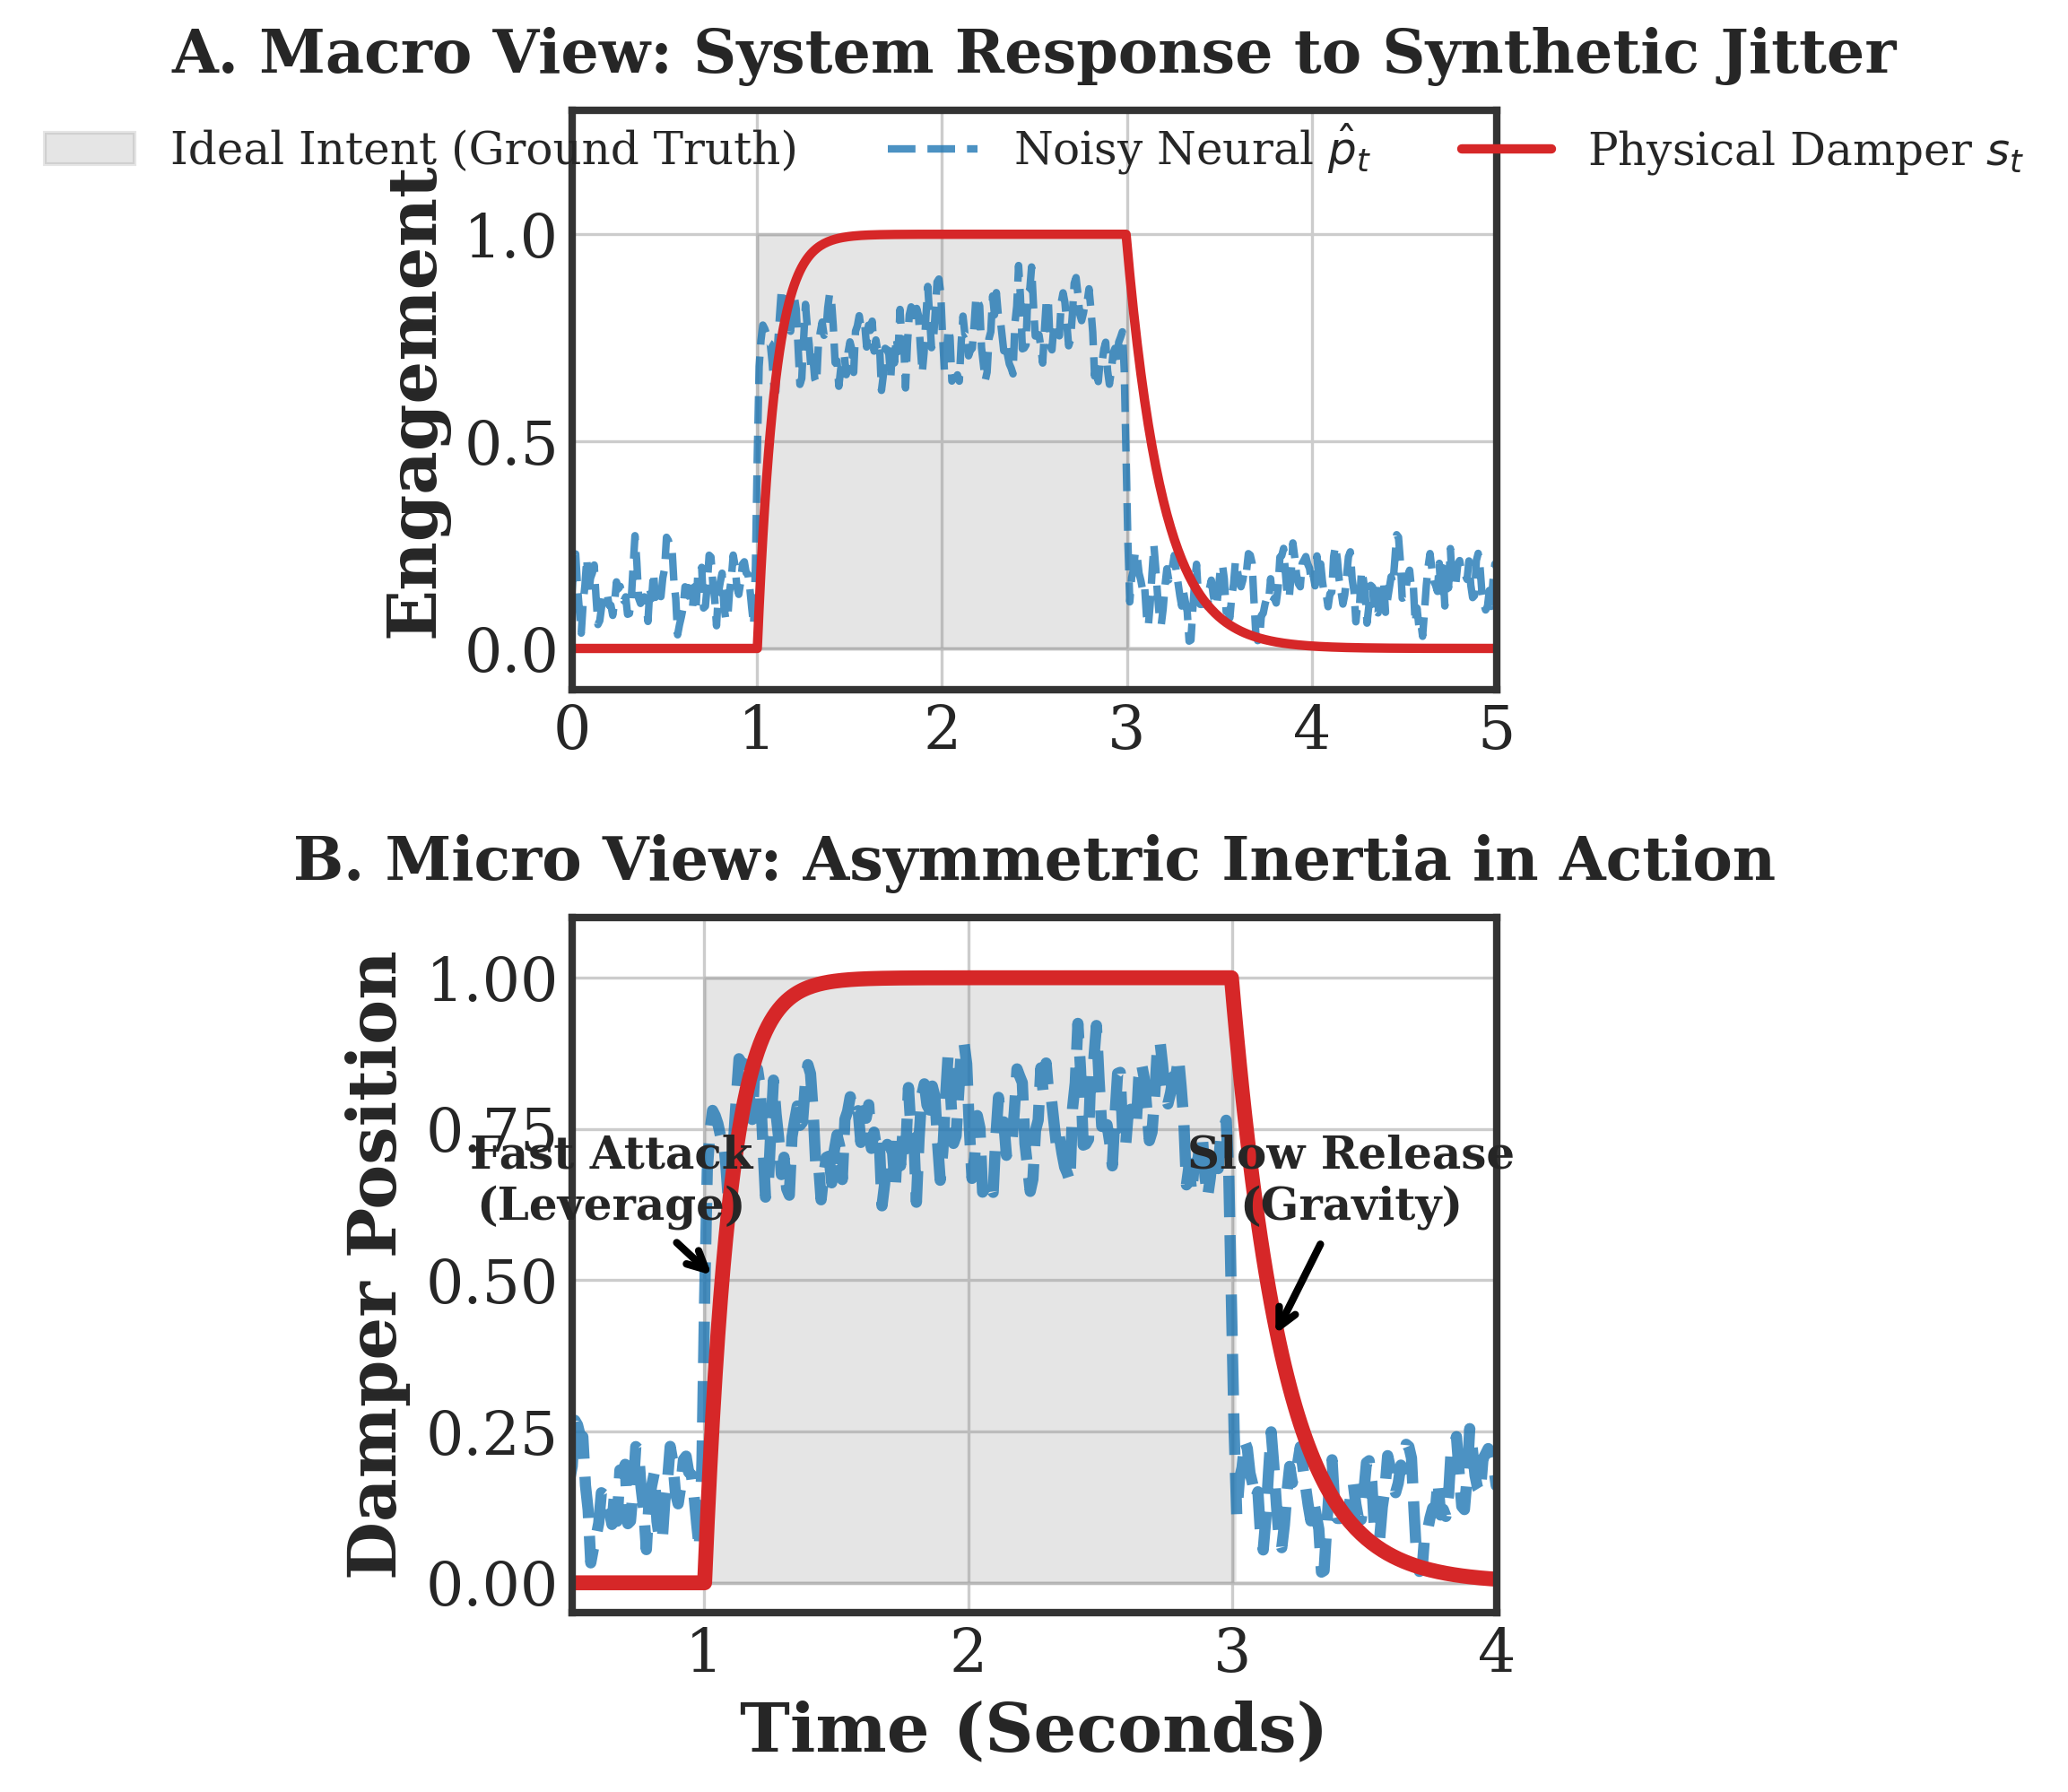

In [4]:
# --- Cell 4: Figure 1 ---
import torch
import numpy as np
import matplotlib.pyplot as plt

# 1. Constructing Synthetic Noisy Neural Prediction
fps = 100  # 16000 / 160
duration = 5.0
time_axis_frames = np.linspace(0, duration, int(duration * fps))

# Initialize base probability
synthetic_probs = np.zeros_like(time_axis_frames)

# Set up the perfect stages
attack_time = 1.0
release_time = 3.0
attack_idx = int(attack_time * fps)
release_idx = int(release_time * fps)

# Injecting "digital jitter": simulating the uncertainty of neural networks
np.random.seed(42)
# Phase 1: Noise level when not pressed (fluctuating between 0 and 0.3)
synthetic_probs[:attack_idx] = np.random.uniform(0.0, 0.3, size=attack_idx)
# Phase 2: Intense high-frequency shaking upon stepping down (erratic jumping between 0.6 and 0.95, simulating failure crossing the 0.5 threshold)
synthetic_probs[attack_idx:release_idx] = np.random.uniform(0.55, 0.95, size=release_idx - attack_idx)
# Phase 3: Noise level after release (fluctuating between 0 and 0.3)
synthetic_probs[release_idx:] = np.random.uniform(0.0, 0.3, size=len(synthetic_probs) - release_idx)

# Slightly smooth the noise to make it look more like real neural network output
synthetic_probs = np.convolve(synthetic_probs, np.ones(3)/3, mode='same')

# 2. The data is fed into the physics engine for inference.
with torch.no_grad():
    # Adjust the shape to [Batch, Channels, Time] -> [1, 1, 500]
    probs_tensor = torch.tensor(synthetic_probs, dtype=torch.float32).unsqueeze(0).unsqueeze(0).to(device)
    mech_out = mechanism(probs_tensor)
    
    # Extract the actual damper position calculated by the physics engine
    pos_np_frames = mech_out['position'].squeeze().cpu().numpy()

# 3. Perfect drawing (double-row layout, precise alignment)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6.46, 7.0), gridspec_kw={'height_ratios': [1, 1.2]})

# To illustrate the "intention," a clean Ground Truth square wave is drawn as a background reference
gt_ideal = np.zeros_like(time_axis_frames)
gt_ideal[attack_idx:release_idx] = 1.0

# Panel A - Macro View
ax1.fill_between(time_axis_frames, 0, gt_ideal, color='gray', alpha=0.2, step='post', label='Ideal Intent (Ground Truth)')
ax1.plot(time_axis_frames, synthetic_probs, color='#1f77b4', linestyle='--', linewidth=2.0, alpha=0.8, label='Noisy Neural $\hat{p}_t$')
ax1.plot(time_axis_frames, pos_np_frames, color='#d62728', linewidth=2.5, label='Physical Damper $s_t$')

ax1.set_title("A. Macro View: System Response to Synthetic Jitter", fontweight='bold', fontsize=16, pad=10)
ax1.set_ylabel("Engagement", fontweight='bold')
ax1.set_xlim(0, 5.0)
ax1.set_ylim(-0.1, 1.3)
ax1.legend(loc='upper center', bbox_to_anchor=(0.5, 1.05), ncol=3, frameon=False, fontsize=12)

# Panel B - Micro View
zoom_start = 0.5
zoom_end = 4.0 

ax2.fill_between(time_axis_frames, 0, gt_ideal, color='gray', alpha=0.2, step='post')
ax2.plot(time_axis_frames, synthetic_probs, color='#1f77b4', linestyle='--', linewidth=3.0, alpha=0.8)
ax2.plot(time_axis_frames, pos_np_frames, color='#d62728', linewidth=4.0)

ax2.annotate('Fast Attack\n(Leverage)', 
             xy=(attack_time + 0.05, 0.5), xytext=(attack_time - 0.35, 0.6),
             arrowprops=dict(facecolor='black', arrowstyle='->', lw=2),
             fontweight='bold', fontsize=12, ha='center')

ax2.annotate('Slow Release\n(Gravity)', 
             xy=(release_time + 0.15, 0.4), xytext=(release_time + 0.45, 0.6),
             arrowprops=dict(facecolor='black', arrowstyle='->', lw=2),
             fontweight='bold', fontsize=12, ha='center')

ax2.set_title("B. Micro View: Asymmetric Inertia in Action", fontweight='bold', fontsize=16, pad=10)
ax2.set_xlabel("Time (Seconds)", fontweight='bold')
ax2.set_ylabel("Damper Position", fontweight='bold')
ax2.set_xlim(zoom_start, zoom_end)
ax2.set_ylim(-0.05, 1.1)

plt.tight_layout()
plt.savefig("fig_control_inertia_synthetic.pdf", bbox_inches='tight')
plt.show()

C:\Users\lenovo\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


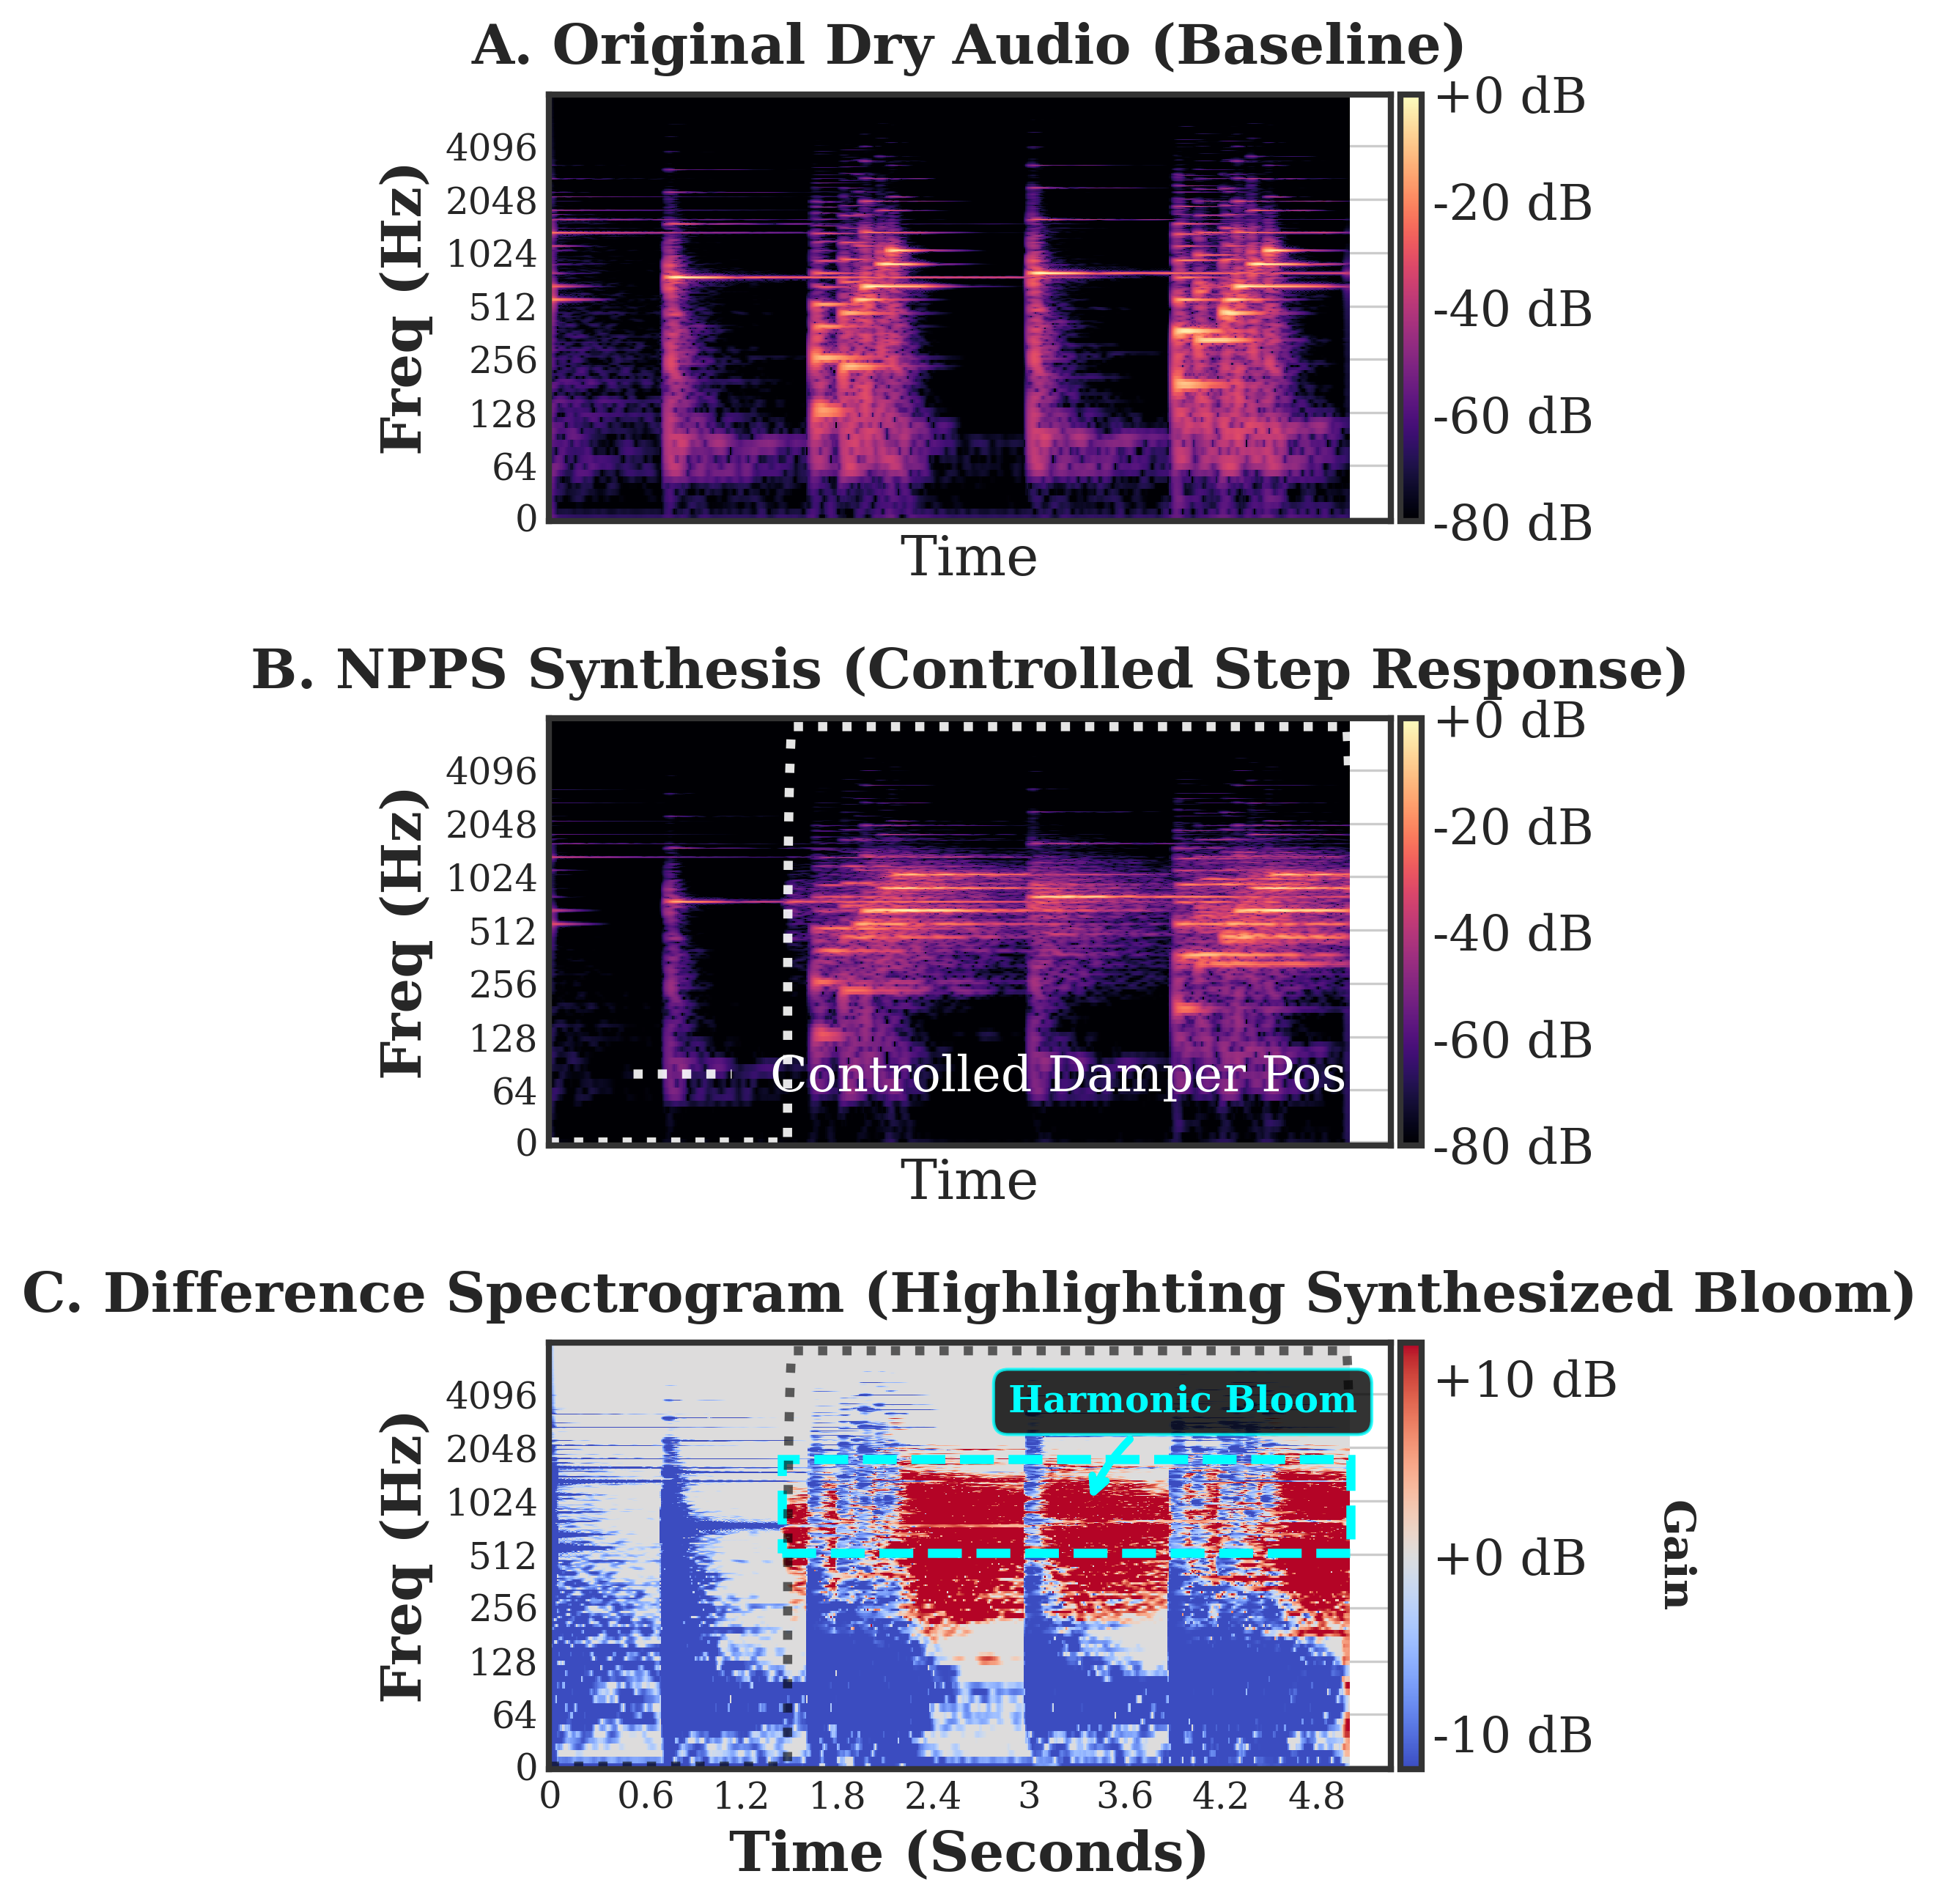

In [5]:
# --- Cell 5: Figure 2 ---
# 1. press the pedal momentarily within 1.5 seconds
fps_audio = 16000
duration_audio = audio_dry.shape[-1]
time_axis_audio = np.linspace(0, 5.0, duration_audio)

# first 1.5 seconds are 0, then instantly pull to 1
pos_controlled = torch.zeros((1, 1, duration_audio)).to(device)
attack_sample = int(1.5 * fps_audio)
pos_controlled[0, 0, attack_sample:] = 1.0 

# use an odd kernel size to perfectly preserve dimensions, and add forced slicing insurance
pos_controlled = torch.nn.functional.avg_pool1d(pos_controlled, kernel_size=401, stride=1, padding=200)
pos_controlled = pos_controlled[:, :, :duration_audio] # Absolute physical alignment insurance

# 2. Running the physics engine
with torch.no_grad():
    audio_baseline = audio_dry.clone() 
    
    # NPPS: Real dry sound + instant pedal pull
    resonance_npps = acoustics(audio_dry, pos_controlled)
    audio_wet_npps = audio_dry + resonance_npps * 2 

audio_dry_np = audio_dry.squeeze().cpu().numpy()
audio_wet_np = audio_wet_npps.squeeze().cpu().numpy()
pos_np_controlled = pos_controlled.squeeze().cpu().numpy()

# 3. Calculate the spectrum
n_fft = 2048
hop_length = 160
sr = 16000

D_dry = librosa.amplitude_to_db(np.abs(librosa.stft(audio_dry_np, n_fft=n_fft, hop_length=hop_length)), ref=np.max)
D_wet = librosa.amplitude_to_db(np.abs(librosa.stft(audio_wet_np, n_fft=n_fft, hop_length=hop_length)), ref=np.max)
min_len = min(D_dry.shape[1], D_wet.shape[1])
D_diff = D_wet[:, :min_len] - D_dry[:, :min_len]

# 4. Draw
fig, axes = plt.subplots(3, 1, figsize=(6.46, 9.0), sharex=True)

# Plot A
ax1 = axes[0]
img1 = librosa.display.specshow(D_dry, y_axis='log', x_axis='time', sr=sr, hop_length=hop_length, ax=ax1, cmap='magma')
ax1.set_title("A. Original Dry Audio (Baseline)", fontweight='bold', pad=10)
cbar1 = fig.colorbar(img1, ax=ax1, format="%+2.0f dB", pad=0.01)

# Plot B
ax2 = axes[1]
img2 = librosa.display.specshow(D_wet, y_axis='log', x_axis='time', sr=sr, hop_length=hop_length, ax=ax2, cmap='magma')
ax2.plot(time_axis_audio, pos_np_controlled * (sr/2)*0.9, color='white', linewidth=3.0, linestyle=':', alpha=0.9, label='Controlled Damper Pos')
ax2.set_title("B. NPPS Synthesis (Controlled Step Response)", fontweight='bold', pad=10)
ax2.legend(loc='lower right', facecolor='black', edgecolor='white', labelcolor='white')
cbar2 = fig.colorbar(img2, ax=ax2, format="%+2.0f dB", pad=0.01)

# Plot C
ax3 = axes[2]
vmax = 12 
img3 = librosa.display.specshow(D_diff, y_axis='log', x_axis='time', sr=sr, hop_length=hop_length, ax=ax3, cmap='coolwarm', vmin=-vmax, vmax=vmax)
ax3.plot(time_axis_audio, pos_np_controlled * (sr/2)*0.9, color='black', linewidth=3.0, linestyle=':', alpha=0.6)
ax3.set_title("C. Difference Spectrogram (Highlighting Synthesized Bloom)", fontweight='bold', pad=10)
cbar3 = fig.colorbar(img3, ax=ax3, format="%+2.0f dB", pad=0.01)
cbar3.set_label("Gain", rotation=270, labelpad=25, fontweight='bold', fontsize=14)

# Intelligent detector based on percentiles and energy centroid
threshold_db = 4.0 # Slightly relax the threshold to capture a more complete overtone cloud boundary

# Obtain the true frequency and time axis mapping
freqs = librosa.fft_frequencies(sr=sr, n_fft=n_fft)
times = librosa.frames_to_time(np.arange(D_diff.shape[1]), sr=sr, hop_length=hop_length)
Time, Freq = np.meshgrid(times, freqs)

# Find pixels that meet the following criteria: occurring after we inject the physical stimulus (>1.5s), avoiding low-frequency fundamental frequencies (>500Hz)
bloom_mask = (D_diff > threshold_db) & (Time >= 1.5) & (Freq > 500)

if np.any(bloom_mask):
    valid_times = Time[bloom_mask]
    valid_freqs = Freq[bloom_mask]
    valid_energies = D_diff[bloom_mask] # Extract the corresponding energy values

    # 1. Use percentiles (Percentiles) to remove outliers and tightly wrap the core region
    t_min = np.min(valid_times)
    t_max = np.percentile(valid_times, 98) # Cut off the long tails

    f_min = np.percentile(valid_freqs, 2)  # The lower boundary
    f_max = np.percentile(valid_freqs, 95) # The upper boundary is extremely crucial: perfectly avoid those white voids above
    
    # 画框
    rect = patches.Rectangle((t_min - 0.05, f_min), 
                             (t_max - t_min) + 0.1, 
                             (f_max - f_min), 
                             linewidth=3.0, edgecolor='cyan', facecolor='none', linestyle='dashed')
    ax3.add_patch(rect)
    
    # 2. Physical energy centroid calculation
    # Replace the susceptible argmax with a more robust approach
    center_t = np.average(valid_times, weights=valid_energies)
    center_f = np.average(valid_freqs, weights=valid_energies)
    
    # The arrow points precisely to the physical center of gravity of this cloud
    ax3.annotate('Harmonic Bloom', 
                 xy=(center_t, center_f), xycoords='data',
                 xytext=(center_t - 0.5, f_max + 1500), textcoords='data',
                 color='cyan', fontweight='bold', fontsize=12,
                 bbox=dict(boxstyle="round,pad=0.4", fc="black", ec="cyan", alpha=0.8),
                 arrowprops=dict(arrowstyle="->", color="cyan", lw=2.5, connectionstyle="arc3,rad=0.2"))
else:
    print("Warning: Bloom energy did not exceed threshold. Bounding box skipped.")

for ax in axes:
    ax.set_ylabel("Freq (Hz)", fontweight='bold')
    ax.tick_params(labelsize=12)

axes[2].set_xlabel("Time (Seconds)", fontweight='bold')
plt.tight_layout()
plt.savefig("fig_spectral_bloom_synthetic_robust.pdf", bbox_inches='tight')
plt.show()